# 02 MODELO MATEMÁTICO-FÍSICO PARA MODELAGEM DINÂMICA GLACIAL, ADVECÇÃO, MISI E DATUM VERTICAL

Este caderno desenvolve a teoria matemática e física que governa o escoamento das geleiras do Mar de Amundsen (Thwaites, Pine Island e Smith–Pope–Kohler) e demonstra como os módulos dinâmicos do pacote (`thwaites.glaciology.advection`, `thwaites.validate.velocity`, `thwaites.diagnostics.vulnerability` e `thwaites.corrections.datum`) separam processos cinemáticos de mudanças reais de massa.


### Roteiro do caderno
| Seção | Fundamentação | Aplicação em código | Módulo |
|---|---|---|---|
| 1 | Conservação de massa: forma Euleriana vs. Lagrangiana | (a) magnitude real de $\mathbf{v}\cdot\nabla h$ no gelo apoiado; (b) plataforma sintética com ondulação advectada | `thwaites.glaciology.advection` |
| 2 | MISI, *buttressing* e classificação dinâmica | (a) fluxo $q_{GL} \propto H^{4,75}$ em leito retrógrado vs. prógrado; (b) classes dinâmicas e correlação corrigida por autocorrelação | `thwaites.diagnostics.vulnerability`, `thwaites.validate.velocity` |
| 3 | Datum vertical e erro de gradiente geoidal | trajetória Lagrangiana sintética com e sem `to_orthometric` | `thwaites.corrections.datum` |
| 4 | Síntese | — | — |

---

## 1. Conservação de Massa Integrada na Vertical: Referencial Euleriano vs. Referencial Lagrangiano

Considere uma coluna de gelo de espessura $H(x, y, t) = h(x, y, t) - b(x, y, t)$ (onde $h$ é a cota da superfície e $b$ é a cota da base do gelo) escoando com velocidade horizontal média na coluna $\mathbf{u}(x, y, t) = (u, v)$. Integrando a equação da continuidade tridimensional $\nabla_3 \cdot \mathbf{u}_3 = 0$ da base $z = b$ ao topo $z = h$ sob as condições cinemáticas de contorno na superfície e na base, obtém-se a **equação fundamental da conservação de massa glacial**:

$$\frac{\partial H}{\partial t} + \nabla\cdot(H\mathbf{u}) = \dot{a}_s - \dot{m}_b$$

onde $\dot{a}_s$ é o balanço de massa superficial (acumulação menos ablação, $\text{SMB}$) e $\dot{m}_b$ é a taxa de derretimento basal (positiva para perda de gelo), ambos expressos em metros de gelo equivalente por ano.

### 1.1 Decomposição da Divergência de Fluxo e o Papel da Advecção
Aplicando a identidade vetorial $\nabla\cdot(H\mathbf{u}) = \mathbf{u}\cdot\nabla H + H(\nabla\cdot\mathbf{u})$, temos duas formas matematicamente equivalentes da lei de conservação:

1. **Forma Euleriana (em coordenadas espaciais fixas $(x, y)$):**
   $$\frac{\partial H}{\partial t} = \dot{a}_s - \dot{m}_b - \underbrace{\mathbf{u}\cdot\nabla H}_{\text{advecção de espessura}} - \underbrace{H(\nabla\cdot\mathbf{u})}_{\text{afinamento por estiramento longitudinal/transversal}}$$
   Integrando sobre um domínio fixo $\Omega$ de gelo apoiado (onde $b$ é o leito rochoso fixo, logo $\partial_t H = \partial_t h$):
   $$\frac{dV}{dt} = \iint_\Omega \frac{\partial h}{\partial t}\,dA = \iint_\Omega (\dot{a}_s - \dot{m}_b)\,dA - \oint_{\partial\Omega} H(\mathbf{u}\cdot\mathbf{n})\,ds$$
   **Implicação crucial (`thwaites.glaciology.advection`):** A integral espacial da taxa Euleriana $\partial h / \partial t$ medida pelo ICESat-2 sobre o domínio apoiado $\Omega$ **já é exatamente a variação total de volume $dV/dt$ daquele domínio!** O termo de transporte $\mathbf{u}\cdot\nabla h$ redistribui massa internamente e cruza a fronteira $\partial\Omega$ (a linha de aterramento), mas **nunca deve ser somado novamente ao balanço de massa regional integrado**, sob pena de contar a descarga dinâmica duas vezes.

2. **Forma Lagrangiana (seguindo a parcela material $\frac{d\mathbf{X}}{dt} = \mathbf{u}(\mathbf{X}, t)$):**
   Definindo a derivada material (substantiva) ao longo da trajetória da coluna de gelo:
   $$\frac{DH}{Dt} \equiv \frac{\partial H}{\partial t} + \mathbf{u}\cdot\nabla H$$
   a equação da continuidade simplifica-se para:
   $$\frac{DH}{Dt} + H(\nabla\cdot\mathbf{u}) = \dot{a}_s - \dot{m}_b \quad \Longrightarrow \quad \dot{m}_b = \dot{a}_s - \frac{DH}{Dt} - H(\nabla\cdot\mathbf{u})$$
   **Por que a forma Lagrangiana é superior para mapear derretimento basal em plataformas rápidas (Moholdt et al., 2014; Shean et al., 2019; Adusumilli et al., 2020):**
   Sobre plataformas que escoam a $1\text{--}4\text{ km/ano}$, a superfície possui ondulações topográficas, fendas e canais basais com gradientes locais $|\nabla H| \sim 10^{-2}\text{--}10^{-1}$. Em uma célula fixa Euleriana, a simples passagem dessas ondulações gera $\partial_t H = -\mathbf{u}\cdot\nabla H$ de dezenas de metros por ano, mascarando completamente $\dot{m}_b$. Ao seguir a parcela material ($DH/Dt$), o termo $\mathbf{u}\cdot\nabla H$ é absorvido cinematicamente sem precisar diferenciar numericamente um campo ruidoso de espessura $\nabla H$, restando apenas a divergência da velocidade $H(\nabla\cdot\mathbf{u})$.

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


,n_valid,adv_median_m_yr,adv_abs_median_m_yr,adv_p90_abs_m_yr,speed_median_m_yr,slope_median
smooth_km,,,,,,
2.0,11602,-0.1363,0.1655,2.0764,44.0525,0.0051
5.0,11602,-0.1535,0.1612,1.8949,44.0525,0.0045
10.0,11602,-0.1574,0.1608,1.7747,44.0525,0.0045
15.0,11602,-0.1468,0.1507,1.6985,44.0525,0.0044


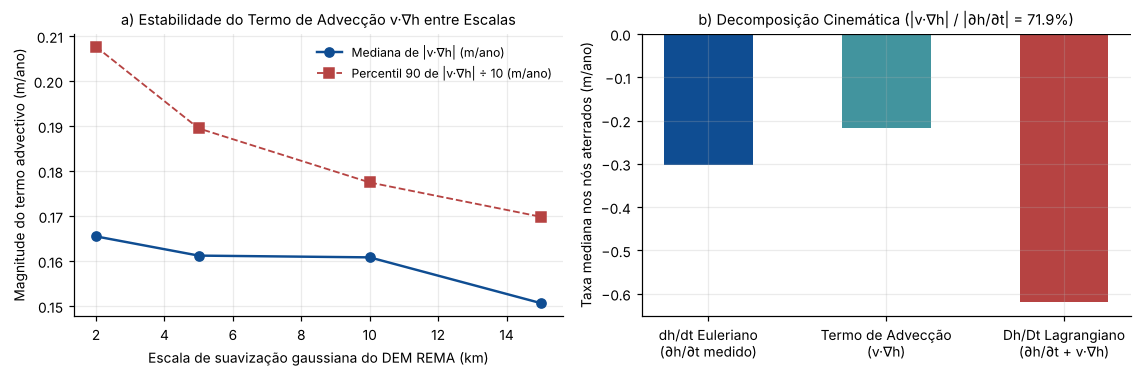

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

adv_sum = json.loads((DATA_DIR / "jja_advection_summary.json").read_text(encoding="utf-8"))
adv_sens = pd.read_csv(DATA_DIR / "jja_advection_sensitivity.csv")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5))
ax[0].plot(adv_sens["smooth_km"], adv_sens["adv_abs_median_m_yr"], "o-", color="#0F4D92", lw=1.6, label="Mediana de |v·∇h| (m/ano)")
ax[0].plot(adv_sens["smooth_km"], adv_sens["adv_p90_abs_m_yr"] / 10.0, "s--", color="#B64342", lw=1.2, label="Percentil 90 de |v·∇h| ÷ 10 (m/ano)")
ax[0].set_xlabel("Escala de suavização gaussiana do DEM REMA (km)")
ax[0].set_ylabel("Magnitude do termo advectivo (m/ano)")
ax[0].set_title("a) Estabilidade do Termo de Advecção v·∇h entre Escalas")
ax[0].legend(frameon=False, fontsize=8)

termos = ["dh/dt Euleriano\n(∂h/∂t medido)", "Termo de Advecção\n(v·∇h)", "Dh/Dt Lagrangiano\n(∂h/∂t + v·∇h)"]
vals = [adv_sum["dhdt_eulerian_median"], adv_sum["advection_median"], adv_sum["dhdt_lagrangian_median"]]
ax[1].bar(termos, vals, color=["#0F4D92", "#42949E", "#B64342"], width=0.5)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("Taxa mediana nos nós aterrados (m/ano)")
ax[1].set_title(f"b) Decomposição Cinemática (|v·∇h| / |∂h/∂t| = {100*adv_sum['abs_advection_over_abs_dhdt']:.1f}%)")
plt.tight_layout()

adv_sens.set_index("smooth_km").round(4)

**Leitura da figura.**
- **(a)** A mediana de $|\mathbf{v}\cdot\nabla h|$ no gelo apoiado é ~0,16 m/ano e quase não depende da escala de suavização do REMA (2–15 km). A cauda (p90 ~2 m/ano) vem dos troncos rápidos. O termo é, portanto, uma propriedade física estável do campo, e não um artefato da escolha da escala.
- **(b)** O termo advectivo vale ~72% de $|\partial h/\partial t|$ na mediana: a taxa Lagrangiana (o que acontece com uma *coluna* de gelo) é cerca do dobro da Euleriana (o que acontece num *ponto fixo*). As duas grandezas respondem a perguntas diferentes, e nenhuma está "errada".
- **Regra do pipeline:** o balanço de massa regional usa a forma Euleriana integrada ($dV/dt = \iint \partial_t h\,dA$), que já contém o transporte. Somar $\mathbf{v}\cdot\nabla h$ contaria a descarga dinâmica duas vezes. Por isso `jja_advection_summary.json` registra a nota *"NÃO aplicar ao balanço de massa Euleriano"*.

### 1.2 Aplicação: por que a forma Lagrangiana é obrigatória sobre as plataformas
Simulamos uma plataforma que escoa a $2\text{ km/ano}$ com ondulações de espessura de $\pm 15\text{ m}$ e comprimento de onda de 15 km (escala de canais basais e ondulações de fluxo) e um afinamento basal **verdadeiro** de $-2\text{ m/ano}$. A amostragem imita o ICESat-2: uma passagem a cada 91 dias durante 6 anos.

,Euleriano (célula fixa),Lagrangiano (parcela)
Mediana (m/ano),-2.768,-2.000
Desvio-padrão entre locais (m/ano),3.985,0.035
Fração com erro > 2 m/ano,0.746,0.000


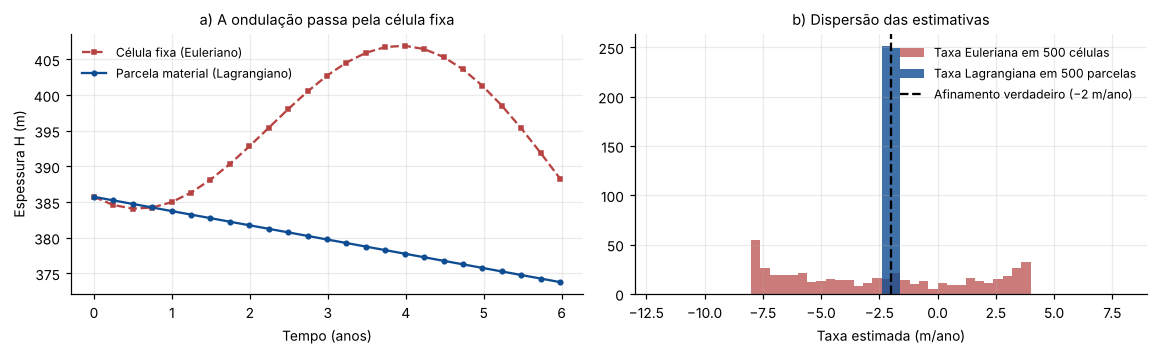

In [3]:
u = 2000.0          # velocidade (m/ano)
A, lam = 15.0, 15_000.0
m_verdadeiro = -2.0 # afinamento verdadeiro da coluna (m/ano)
t_obs = np.arange(0, 6, 91 / 365.25)

def H(x, t):
    """Espessura: ondulação transportada pelo fluxo + afinamento uniforme."""
    return 400.0 + A * np.sin(2 * np.pi * (x - u * t) / lam) + m_verdadeiro * t

rng = np.random.default_rng(2)
x_fixos = rng.uniform(0, 40_000, 500)                         # 500 células Eulerianas fixas
taxa_euler = np.array([np.polyfit(t_obs, H(x0, t_obs) + rng.normal(0, 0.3, t_obs.size), 1)[0] for x0 in x_fixos])
x_parcelas = rng.uniform(0, 40_000, 500)                      # 500 parcelas materiais X(t) = X0 + u t
taxa_lagr = np.array([np.polyfit(t_obs, H(x0 + u * t_obs, t_obs) + rng.normal(0, 0.3, t_obs.size), 1)[0] for x0 in x_parcelas])

fig, ax = plt.subplots(1, 2, figsize=(10.6, 3.3))
x0 = 12_000.0
ax[0].plot(t_obs, H(x0, t_obs), "s--", color="#B64342", ms=3, label="Célula fixa (Euleriano)")
ax[0].plot(t_obs, H(x0 + u * t_obs, t_obs), "o-", color="#0F4D92", ms=3, label="Parcela material (Lagrangiano)")
ax[0].set_xlabel("Tempo (anos)"); ax[0].set_ylabel("Espessura H (m)")
ax[0].set_title("a) A ondulação passa pela célula fixa"); ax[0].legend(frameon=False, fontsize=8)
bins = np.linspace(-12, 8, 51)
ax[1].hist(taxa_euler, bins=bins, color="#B64342", alpha=0.7, label="Taxa Euleriana em 500 células")
ax[1].hist(taxa_lagr, bins=bins, color="#0F4D92", alpha=0.8, label="Taxa Lagrangiana em 500 parcelas")
ax[1].axvline(m_verdadeiro, color="k", ls="--", label="Afinamento verdadeiro (−2 m/ano)")
ax[1].set_xlabel("Taxa estimada (m/ano)"); ax[1].set_title("b) Dispersão das estimativas")
ax[1].legend(frameon=False, fontsize=8); plt.tight_layout()

pd.DataFrame({"Euleriano (célula fixa)": [np.median(taxa_euler), np.std(taxa_euler), np.mean(np.abs(taxa_euler - m_verdadeiro) > 2)],
              "Lagrangiano (parcela)": [np.median(taxa_lagr), np.std(taxa_lagr), np.mean(np.abs(taxa_lagr - m_verdadeiro) > 2)]},
             index=["Mediana (m/ano)", "Desvio-padrão entre locais (m/ano)", "Fração com erro > 2 m/ano"]).round(3)

**Leitura do resultado.** Seguindo a parcela, todas as estimativas ficam em torno de $-2\text{ m/ano}$. Na célula fixa, até a mediana regional se desloca, porque em 6 anos as fases não se compensam por completo. Pior: cada célula individual erra por metros por ano conforme a fase da ondulação que a atravessa (ver o desvio-padrão e a fração com erro > 2 m/ano). Num mapa de derretimento basal, isso apareceria como faixas alternadas de "derretimento" e "congelamento" alinhadas ao relevo, multiplicadas por ~9,3 pela conversão hidrostática. É o problema que o Caderno 06 evita com células materiais Lagrangianas.

---
## 2. Mecânica da Instabilidade do Manto de Gelo Marinho (MISI), *Buttressing* e Classificação Dinâmica

### 2.1 Fluxo na Linha de Aterramento e Leito Retrógrado (Weertman, 1974; Schoof, 2007; Gudmundsson, 2013)
Na ausência de contenção lateral ou frontal por uma plataforma flutuante (*unbuttressed marine ice sheet*), a análise assintótica de camada limite de Schoof (2007, *JGR*) mostra que o fluxo de gelo $q_{\text{GL}} = H_{\text{GL}} u_{\text{GL}}$ através da linha de aterramento é uma função fortemente não-linear da espessura na linha de aterramento $H_{\text{GL}}$ e do fator de contenção (*buttressing*) $\Theta \in (0, 1]$ — a razão entre a tensão longitudinal na linha de aterramento com e sem a plataforma ($\Theta = 1$: sem contenção; $\Theta < 1$: a plataforma segura o fluxo):

$$q_{\text{GL}} = \left(\frac{A (\rho_i g)^{n+1} (1 - \rho_i/\rho_w)^n}{4^n C}\right)^{\frac{1}{m+1}} \Theta^{\frac{n}{m+1}} H_{\text{GL}}^{\frac{m + n + 3}{m + 1}}$$

onde $A$ e $n \approx 3$ são os parâmetros da lei de fluência de Glen ($\dot{\varepsilon}_{ij} = A \tau_e^{n-1} \tau_{ij}$), $C$ e $m \approx 1/3$ são os parâmetros da lei de atrito basal de Weertman ($\tau_b = C u^m$), dando um expoente superlinear $\gamma = (m+n+3)/(m+1) \approx 19/4 = 4{,}75$. Pela condição de flutuação hidrostática na linha de aterramento, $H_{\text{GL}} = -(\rho_w/\rho_i) b(x_{\text{GL}})$.

Se o leito marinho aprofunda para o interior continental — **declive retrógrado**, definido em `thwaites.diagnostics.vulnerability.along_flow_bed_slope` por:
$$S_{\text{bed, fluxo}} = \frac{\nabla b \cdot \mathbf{u}}{\|\mathbf{u}\|} > 0$$
então qualquer recuo da linha de aterramento para águas mais profundas aumenta $H_{\text{GL}}$, o que eleva a descarga $q_{\text{GL}} \propto H_{\text{GL}}^{4{,}75}$, provocando maior afinamento dinâmico e novo recuo (**MISI**). Quando o derretimento basal afina a plataforma flutuante ou a zona de cisalhamento se fragmenta (Wild et al., 2022), a contenção diminui e $\Theta$ **aumenta** em direção a 1, acelerando o escoamento a montante mesmo antes que a geometria local mude.

### 2.2 Classificação Dinâmica Conjunta ($\text{dh/dt} \times \|\mathbf{u}\|$) e Precursores Dinâmicos (`thwaites.validate.velocity`)
Cruzar a taxa altimétrica $\text{dh/dt}$ com a velocidade superficial $\|\mathbf{u}\|$ evita o erro clássico de declarar uma região interior como "dinamicamente estável" apenas porque $|\text{dh/dt}|$ é pequeno:
- Nós onde $|\text{dh/dt}| \le 1{,}96\,\sigma_{\text{dh/dt}}$ **mas** $\|\mathbf{u}\| \ge 100\text{ m/ano}$ (`sem_tendencia_mas_fluxo_rapido`, $202$ nós identificados no domínio) constituem possíveis **precursores dinâmicos** (troncos de escoamento rápido onde o afinamento ainda é compensado temporariamente por convergência ou acumulação);
- **Correção obrigatória por autocorrelação espacial (`correlation_with_autocorrelation`):** A correlação de Spearman entre $\text{dh/dt}$ e $\|\mathbf{u}\|$ em $8.656$ nós é $r_s = -0{,}618$. Um teste ingênuo que trate os $8.656$ nós como independentes devolve $p \approx 0$ ("altamente significativo"), mas com o comprimento de correlação conservador $L = 154{,}4\text{ km}$ existem apenas $n_{\text{eff}} = A/(\pi L^2) = 5{,}34$ graus de liberdade espaciais independentes, resultando em $p_{\text{corrigido}} = 0{,}237$ (não significativo globalmente!).

### 2.3 Aplicação: sensibilidade do fluxo na linha de aterramento à geometria do leito
Usando a lei de Schoof (2007), $q_{GL} \propto \Theta^{n/(m+1)}\,H_{GL}^{(m+n+3)/(m+1)}$ com $n = 3$ e $m = 1/3$, e a condição de flutuação $H_{GL} = -(\rho_w/\rho_i)\,b(x_{GL})$, calculamos como a descarga muda quando a linha de aterramento recua 30 km sobre um leito **retrógrado** (aprofunda para o interior, 10 m/km) e sobre um leito **prógrado** (sobe para o interior):

Recuo de 10 km em leito retrógrado: H_GL 672 → 784 m (+17%), descarga +108%
Perda de contenção Θ = 0,60 → 0,75: descarga × 1.65 com a mesma geometria do leito


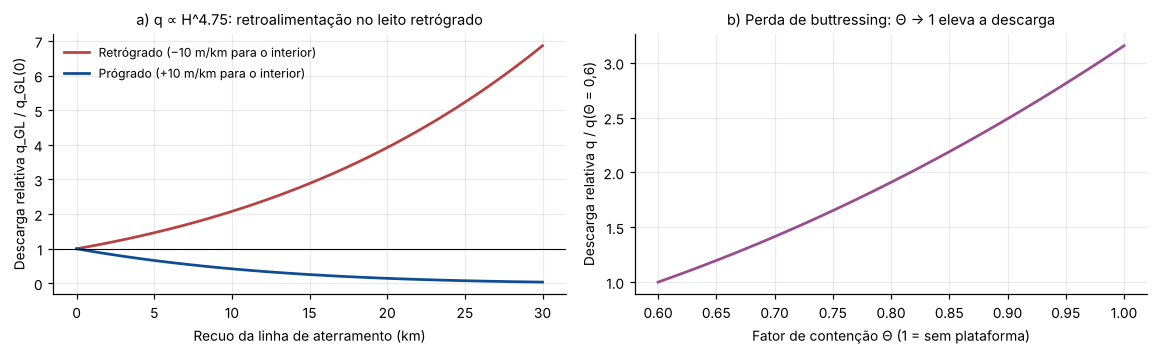

In [4]:
RHO_I, RHO_W = 917.0, 1027.0
n_glen, m_atr = 3.0, 1.0 / 3.0
expo_H = (m_atr + n_glen + 3) / (m_atr + 1)          # 4,75
expo_T = n_glen / (m_atr + 1)                        # 2,25

recuo_km = np.linspace(0, 30, 61)
b0 = -600.0
leitos = {"Retrógrado (−10 m/km para o interior)": b0 - 10.0 * recuo_km,
          "Prógrado (+10 m/km para o interior)": b0 + 10.0 * recuo_km}

fig, ax = plt.subplots(1, 2, figsize=(10.6, 3.3))
for (nome, b), cor in zip(leitos.items(), ["#B64342", "#0F4D92"]):
    H_gl = -(RHO_W / RHO_I) * b
    ax[0].plot(recuo_km, (H_gl / H_gl[0]) ** expo_H, color=cor, lw=1.8, label=nome)
ax[0].axhline(1, color="k", lw=0.7)
ax[0].set_xlabel("Recuo da linha de aterramento (km)"); ax[0].set_ylabel("Descarga relativa q_GL / q_GL(0)")
ax[0].set_title(f"a) q ∝ H^{expo_H:.2f}: retroalimentação no leito retrógrado"); ax[0].legend(frameon=False, fontsize=8)

theta0 = 0.6                                         # estado inicial: plataforma contendo o fluxo
theta = np.linspace(theta0, 1.0, 41)
ax[1].plot(theta, (theta / theta0) ** expo_T, color="#9A4D8E", lw=1.8)
ax[1].set_xlabel("Fator de contenção Θ (1 = sem plataforma)"); ax[1].set_ylabel("Descarga relativa q / q(Θ = 0,6)")
ax[1].set_title("b) Perda de buttressing: Θ → 1 eleva a descarga")
plt.tight_layout()

H_ret = -(RHO_W / RHO_I) * leitos["Retrógrado (−10 m/km para o interior)"]
print(f"Recuo de 10 km em leito retrógrado: H_GL {H_ret[0]:.0f} → {H_ret[20]:.0f} m (+{100*(H_ret[20]/H_ret[0]-1):.0f}%), "
      f"descarga +{100*((H_ret[20]/H_ret[0])**expo_H - 1):.0f}%")
print(f"Perda de contenção Θ = 0,60 → 0,75: descarga × {(0.75 / 0.60) ** expo_T:.2f} com a mesma geometria do leito")

**Leitura.** No leito retrógrado, cada quilômetro de recuo aumenta a espessura na linha de aterramento e, pelo expoente 4,75, aumenta a descarga desproporcionalmente. Mais descarga causa mais afinamento e mais recuo: essa é a retroalimentação positiva da MISI. No leito prógrado ocorre o oposto, e o recuo se autolimita. O painel (b) mostra o outro gatilho: reduzir o *buttressing* (afinamento da plataforma, fratura da margem de cisalhamento) leva $\Theta$ em direção a 1 e eleva a descarga sem que a geometria do leito mude.

A lei de Schoof vale para fluxo bidimensional sem contenção lateral. Aqui ela é usada como **guia qualitativo** da sensibilidade, não como previsão da descarga da Thwaites. O pipeline não estima $q_{GL}$; ele mede as consequências observáveis (dh/dt, recuo da linha de aterramento, Caderno 08) e usa `along_flow_bed_slope` para identificar onde o leito é retrógrado.

In [5]:
from thwaites.diagnostics.vulnerability import along_flow_bed_slope

dyn_sum = json.loads((DATA_DIR / "jja_dynamics_summary.json").read_text(encoding="utf-8"))

# Demonstração do cálculo de declive retrógrado do leito ao longo do fluxo (along_flow_bed_slope)
x_g = np.linspace(0, 60_000, 61)
y_g = np.linspace(0, 40_000, 41)
XG, YG = np.meshgrid(x_g, y_g)
# Leito que aprofunda para o interior (x crescente = direção para o oceano, b sobe de -1200 m para -500 m)
bed_retro = -1200.0 + 0.012 * XG + 80.0 * np.cos(YG / 8000.0)
vx_sim = np.full_like(XG, 800.0)
vy_sim = np.zeros_like(YG)
s_along = along_flow_bed_slope(bed_retro, x_g, y_g, vx_sim, vy_sim)

cls_df = pd.DataFrame([
    {"Classe Dinâmica Conjunta (dh/dt × velocidade)": k, "Número de Nós": v, "Fração (%)": 100 * v / dyn_sum["n_nodes"]}
    for k, v in dyn_sum["class_counts"].items()
]).set_index("Classe Dinâmica Conjunta (dh/dt × velocidade)")

print(f"Declive longitudinal médio do leito simulado: {np.nanmean(s_along):+.2f} m/km (> 0 confirma leito retrógrado)")
print(f"Correlação dh/dt × velocidade: r_Spearman = {dyn_sum['assoc_dhdt_speed']['spearman_r']:.3f} | "
      f"p_ingênuo (n={dyn_sum['assoc_dhdt_speed']['n']}) = {dyn_sum['assoc_dhdt_speed']['p_naive']:.2e} -> "
      f"p_corrigido (n_eff={dyn_sum['assoc_dhdt_speed']['n_effective']:.2f}) = {dyn_sum['assoc_dhdt_speed']['p_autocorr_corrected']:.3f}")
cls_df.round(2)

Declive longitudinal médio do leito simulado: +12.00 m/km (> 0 confirma leito retrógrado)
Correlação dh/dt × velocidade: r_Spearman = -0.618 | p_ingênuo (n=8656) = 0.00e+00 -> p_corrigido (n_eff=5.34) = 0.237


,Número de Nós,Fração (%)
Classe Dinâmica Conjunta (dh/dt × velocidade),,
adelgaçamento_significativo_fluxo_lento,3407,39.18
adelgaçamento_significativo_fluxo_rapido,2643,30.40
estavel_conjunto,1949,22.42
inconclusivo,494,5.68
sem_tendencia_mas_fluxo_rapido,202,2.32


**Leitura do resultado.**
- **Classes dinâmicas:** 70% dos nós têm afinamento significativo, e quase metade deles está em fluxo rápido. Os **202 nós** `sem_tendencia_mas_fluxo_rapido` merecem atenção: escoam a mais de 100 m/ano sem afinamento detectável, o que caracteriza candidatos a *precursores dinâmicos*, onde o afinamento pode estar sendo compensado por acumulação ou convergência de fluxo.
- **Correlação dh/dt × velocidade:** $r_s = -0{,}62$ é forte, mas os 8.656 nós não são 8.656 amostras independentes. Com $L = 154\text{ km}$ restam $n_{\text{eff}} \approx 5{,}3$ graus de liberdade espaciais, e o $p$ sobe de $\approx 0$ para $0{,}24$. A associação é física e plausível (o afinamento concentra-se nos troncos rápidos), mas, **com a geometria de uma única bacia, não há amostras independentes suficientes para afirmá-la como lei estatística**. Ver Caderno 00, §2.10.
- O `along_flow_bed_slope` sintético retorna $+12\text{ m/km}$, exatamente o gradiente imposto ($0{,}012$): o sinal positivo identifica leito retrógrado no sentido do fluxo.

---
## 3. Harmonização de Datum Vertical e Erro de Gradiente Geoidal em Trajetórias Lagrangianas (`thwaites.corrections.datum`)

O produto ATL06 fornece elevações $h_{\text{LI}}$ referenciadas ao **elipsoide matemático WGS84**. Entretanto, a superfície equipotencial do campo de gravidade terrestre (o **geoide** $N_{\text{EIGEN-6C4}}$, Förste et al., 2014) e a topografia dinâmica média do oceano ($\text{MDT}_{\text{DTU15}}$) variam espacialmente: na região do Mar de Amundsen, $N$ varia de $-34{,}4\text{ m}$ a $-19{,}1\text{ m}$ ($\Delta N \approx 15{,}3\text{ m}$).

- **Em um nó fixo Euleriano $(x_0, y_0)$:** como $\partial_t N(x_0, y_0) = 0$, a ondulação geoidal cancela exatamente na derivada temporal $\partial_t (h - N) = \partial_t h$;
- **Em uma trajetória Lagrangiana $\mathbf{X}(t)$:** a parcela de gelo percorre $\Delta \mathbf{X} = \mathbf{u}\,\Delta t$ ($7\text{ a }28\text{ km}$ em 7 anos). Se $h$ não for convertida para altura ortométrica/física acima do nível médio do mar ($h^* = h_{\text{WGS84}} - N_{\text{EIGEN-6C4}} - \text{MDT}_{\text{DTU15}}$), a derivada material sobre o elipsoide contém um **viés geoidal cinemático**:
  $$\left(\frac{Dh}{Dt}\right)_{\text{elipsoide}} = \left(\frac{Dh^*}{Dt}\right)_{\text{físico}} + \mathbf{u}\cdot\nabla(N + \text{MDT})$$
  Multiplicado pelo fator hidrostático $\rho_w/(\rho_w - \rho_i) \approx 9{,}34$, um erro de gradiente geoidal de $0{,}064\text{ m/ano}$ em $h$ induziria **$0{,}60\text{ m/ano}$ de erro sistemático em $DH/Dt$ e em $m_b$** (Seeger & Minderhoud, 2026; Chartrand et al., 2024). Por isso o pipeline subtrai explicitamente $N_{\text{EIGEN-6C4}} + \text{MDT}_{\text{DTU15}}$ antes de qualquer cálculo hidrostático ou Lagrangiano.

### 3.1 Aplicação: trajetória Lagrangiana sobre um geoide inclinado
Uma parcela de gelo flutuante percorre 25 km em 6 anos sobre um geoide com gradiente de $1{,}5\text{ cm/km}$ (próximo ao gradiente mediano ao longo dos troncos rápidos). A superfície física está afinando a $-0{,}50\text{ m/ano}$. Comparamos a taxa medida sobre o elipsoide com a taxa após `to_orthometric`:

In [6]:
from thwaites.corrections.datum import to_orthometric

t_p = np.linspace(0, 6, 25)
x_p = 25_000.0 * t_p / 6.0                               # posição ao longo do fluxo (m)
N_geoide = -30.0 + 0.015e-3 * x_p                        # geoide: −30 m + 1,5 cm/km
h_fisica = 45.0 - 0.50 * t_p                             # altura acima do nível do mar (verdade)
h_elipsoide = h_fisica + N_geoide                        # o que o ATL06 entrega (WGS84)

taxa_elip = np.polyfit(t_p, h_elipsoide, 1)[0]
taxa_orto = np.polyfit(t_p, to_orthometric(h_elipsoide, N_geoide), 1)[0]
fator_hidro = RHO_W / (RHO_W - RHO_I)

pd.DataFrame({
    "Dh/Dt de superfície (m/ano)": [taxa_elip, taxa_orto, -0.50],
    "DH/Dt hidrostático = 9,34 × Dh/Dt (m/ano)": [fator_hidro * taxa_elip, fator_hidro * taxa_orto, fator_hidro * -0.50],
}, index=["Sobre o elipsoide WGS84 (sem harmonizar)", "Após to_orthometric (h − N)", "Verdade"]).round(3)

,Dh/Dt de superfície (m/ano),"DH/Dt hidrostático = 9,34 × Dh/Dt (m/ano)"
Sobre o elipsoide WGS84 (sem harmonizar),-0.438,-4.085
Após to_orthometric (h − N),-0.500,-4.668
Verdade,-0.500,-4.668


**Leitura.** Sem harmonizar o datum, a parcela "sobe" junto com o geoide, e o afinamento de superfície aparece ~13% menor. Depois da conversão hidrostática, o erro vira $\sim 0{,}6\text{ m/ano}$ em espessura e, portanto, em derretimento basal, o mesmo valor da tabela acima para os troncos rápidos. Num ponto fixo Euleriano esse erro é nulo, porque $\partial_t N = 0$. Ele só aparece quando se segue o gelo, e por isso a correção é obrigatória na cadeia basal Lagrangiana, mas irrelevante para o dh/dt do gelo apoiado.

In [7]:
# Quantificação do erro espúrio de taxa induzido pelo gradiente do geoide EIGEN-6C4 na ASE
geoid_table = pd.DataFrame([
    {"Deslocamento Lagrangiano da Parcela (2019–2025)": "< 5 km (plataformas lentas: Cosgrove)", "|ΔN| Mediano (m)": 0.011, "Viés em Dh/Dt (m/ano)": 0.0019, "Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)": 0.0019 * 9.336},
    {"Deslocamento Lagrangiano da Parcela (2019–2025)": "5 – 10 km (Dotson / Crosson)", "|ΔN| Mediano (m)": 0.065, "Viés em Dh/Dt (m/ano)": 0.0108, "Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)": 0.0108 * 9.336},
    {"Deslocamento Lagrangiano da Parcela (2019–2025)": "> 20 km (troncos rápidos: PIG e Thwaites)", "|ΔN| Mediano (m)": 0.381, "Viés em Dh/Dt (m/ano)": 0.0636, "Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)": 0.0636 * 9.336},
]).set_index("Deslocamento Lagrangiano da Parcela (2019–2025)")
geoid_table.round(4)

,|ΔN| Mediano (m),Viés em Dh/Dt (m/ano),"Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)"
Deslocamento Lagrangiano da Parcela (2019–2025),,,
< 5 km (plataformas lentas: Cosgrove),0.011,0.0019,0.0177
5 – 10 km (Dotson / Crosson),0.065,0.0108,0.1008
> 20 km (troncos rápidos: PIG e Thwaites),0.381,0.0636,0.5938


---
## 4. Síntese do Caderno

| Questão física | Resposta do pipeline | Evidência |
|---|---|---|
| Euleriano ou Lagrangiano? | Euleriano para o balanço de massa do gelo apoiado; Lagrangiano para derretimento basal nas plataformas | §1: advecção = 72% de $\lvert\partial_t h\rvert$; a célula fixa erra vários m/ano sob ondulações advectadas |
| Contar a advecção no balanço de massa? | **Não**: $\iint \partial_t h\,dA$ já é $dV/dt$ | identidade de divergência (§1.1) |
| Por que a Thwaites é vulnerável? | leito retrógrado + perda de *buttressing* | $q_{GL} \propto H^{4,75}$ (§2.3) |
| dh/dt e velocidade estão associados? | fisicamente sim; estatisticamente, $n_{\text{eff}} \approx 5$ não basta | $p$ corrigido = 0,24 (§2.2) |
| Datum vertical | subtrair $N_{\text{EIGEN-6C4}} + \text{MDT}_{\text{DTU15}}$ antes de qualquer cálculo Lagrangiano | erro evitado de até ~0,6 m/ano em $m_b$ (§3) |

**Scripts do pipeline:** `pipelines/gelo_apoiado/run_advection.py`, `run_dynamics.py`, `run_velocity_check.py`, `run_vertical_reference.py`, `run_vertical_reference_audit.py`.

**Próximo caderno:** o Caderno 03 aplica a forma Euleriana ao gelo apoiado e estima o campo de dh/dt nó a nó.